In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel('marketing_campaign.xlsx')
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,5,0,0,0,0,0,0,3,11,0


In [4]:
print("Shape:", df.shape)
print(df.isnull().sum())
print("Duplicate:", df.duplicated().sum())

Shape: (2240, 29)
ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Complain                0
Z_CostContact           0
Z_Revenue               0
Response                0
dtype: int64
Duplicate: 0


In [5]:
df_clean = df.copy()
df_clean = df_clean.drop_duplicates()
print("Nava Shape after duplicate:", df_clean.shape)

Nava Shape after duplicate: (2240, 29)


In [6]:
median_income = df_clean['Income'].median()
print("Median Income:", median_income)

df_clean['Income'] = df_clean['Income'].fillna(median_income)
print("Ata Income missing:", df_clean['Income'].isnull().sum())

Median Income: 51381.5
Ata Income missing: 0


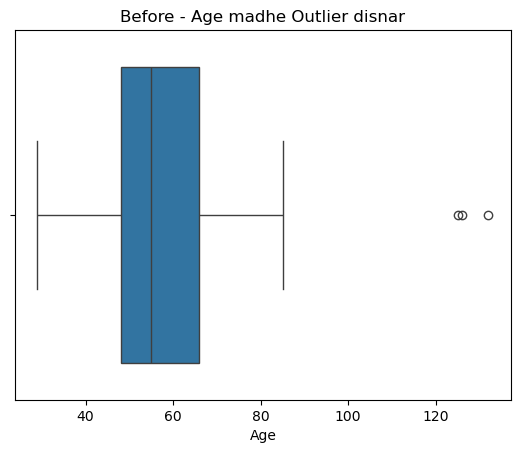

Normal Age 18 to 90 cha baherche error manun kadhu


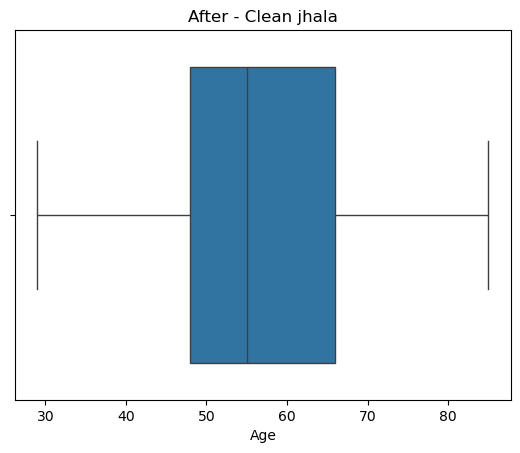

Clean shape: (2237, 30)


In [7]:
df_clean['Age'] = 2025 - df_clean['Year_Birth']

import matplotlib.pyplot as plt
import seaborn as sns

sns.boxplot(x=df_clean['Age'])
plt.title("Before - Age madhe Outlier disnar")
plt.show()

# IQR rule
Q1 = df_clean['Age'].quantile(0.25)
Q3 = df_clean['Age'].quantile(0.75)
IQR = Q3 - Q1
print("Normal Age 18 to 90 cha baherche error manun kadhu")

df_clean = df_clean[(df_clean['Age'] <= 90) & (df_clean['Age'] >= 18)]

sns.boxplot(x=df_clean['Age'])
plt.title("After - Clean jhala")
plt.show()
print("Clean shape:", df_clean.shape)

In [8]:
df_clean = pd.get_dummies(df_clean, columns=['Education','Marital_Status'], drop_first=True)
df_clean.head()

,ID,Year_Birth,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,...,Education_Graduation,Education_Master,Education_PhD,Marital_Status_Alone,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow,Marital_Status_YOLO
0,5524,1957,58138.0,0,0,2012-09-04,58,635,88,546,...,True,False,False,False,False,False,True,False,False,False
1,2174,1954,46344.0,1,1,2014-03-08,38,11,1,6,...,True,False,False,False,False,False,True,False,False,False
2,4141,1965,71613.0,0,0,2013-08-21,26,426,49,127,...,True,False,False,False,False,False,False,True,False,False
3,6182,1984,26646.0,1,0,2014-02-10,26,11,4,20,...,True,False,False,False,False,False,False,True,False,False
4,5324,1981,58293.0,1,0,2014-01-19,94,173,43,118,...,False,False,True,False,False,True,False,False,False,False


In [9]:
print("BEFORE:", df.shape, "Missing:", df.isnull().sum().sum(), "Dup:", df.duplicated().sum())
print("AFTER:", df_clean.shape, "Missing:", df_clean.isnull().sum().sum(), "Dup:", df_clean.duplicated().sum())

df_clean.to_csv('cleaned_data.csv', index=False)
print("cleaned_data.csv save jhala!")

BEFORE: (2240, 29) Missing: 24 Dup: 0
AFTER: (2237, 39) Missing: 0 Dup: 0
cleaned_data.csv save jhala!
